# 04 · El viaje de la flor hasta un altar en Hermosillo

¿Qué tan lejos crece la flor? Trazamos la ruta por carretera (OSRM) desde cada municipio que sembró cempasúchil entre 2021 y 2025 hasta Hermosillo, y la ponderamos por superficie sembrada.

La ruta parte del centro geográfico que devuelve Nominatim para cada municipio, así que es aproximada (±20 km). Que una flor se siembre lejos no prueba que llegue a Hermosillo: el SIAP no registra a dónde se vende. Sí dice de dónde **podría** venir.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import plotly.graph_objects as go

from src import config, tema

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

estatal = pd.read_csv(config.DIR_PROCESSED / "cempasuchil_estatal.csv")
municipal = pd.read_csv(config.DIR_PROCESSED / "cempasuchil_municipal.csv")
FUENTE_SIAP = "Fuente: SIAP, Cierre de la Producción Agrícola 1980-2025. Análisis: Sahuaris."

In [2]:
rutas = pd.read_csv(config.DIR_PROCESSED / "rutas_hermosillo.csv")
ANIOS = range(2021, 2026)
ha_mun = (municipal[municipal["anio"].isin(ANIOS)]
          .groupby(["idestado", "nomestado", "idmunicipio", "nommunicipio"], as_index=False)["sembrada"].sum())
ha_mun["ha_promedio"] = ha_mun["sembrada"] / len(ANIOS)
viaje = ha_mun.merge(rutas[["idestado", "idmunicipio", "lat", "lon", "distancia_km", "duracion_h"]], on=["idestado", "idmunicipio"], how="left")
sin_ruta = viaje[viaje["distancia_km"].isna()]
print(f"{len(viaje)} municipios; {len(sin_ruta)} sin ruta ({sin_ruta['ha_promedio'].sum() / viaje['ha_promedio'].sum() * 100:.1f}% de la superficie)")
sin_ruta[["nomestado", "nommunicipio", "ha_promedio"]]

133 municipios; 1 sin ruta (0.2% de la superficie)


,nomestado,nommunicipio,ha_promedio
60,Oaxaca,"H. V. Tezoatlán de Segura y Luna, C. de la I.d...",3.722


In [3]:
con_ruta = viaje.dropna(subset=["distancia_km"])
media_ponderada = (con_ruta["distancia_km"] * con_ruta["ha_promedio"]).sum() / con_ruta["ha_promedio"].sum()
ordenado = con_ruta.sort_values("distancia_km")
ordenado["pct_acum"] = ordenado["ha_promedio"].cumsum() / ordenado["ha_promedio"].sum() * 100
mediana = ordenado.loc[ordenado["pct_acum"] >= 50, "distancia_km"].iloc[0]
lejos = con_ruta.loc[con_ruta["distancia_km"] >= 1500, "ha_promedio"].sum() / con_ruta["ha_promedio"].sum() * 100
cerca = con_ruta.loc[con_ruta["distancia_km"] < 500, "ha_promedio"].sum() / con_ruta["ha_promedio"].sum() * 100
print(f"Distancia promedio ponderada por superficie: {media_ponderada:,.0f} km")
print(f"Mediana ponderada: {mediana:,.0f} km")
print(f"Superficie a 1,500 km o más de Hermosillo: {lejos:.1f}%  |  a menos de 500 km: {cerca:.2f}%")
con_ruta.sort_values("ha_promedio", ascending=False)[["nomestado", "nommunicipio", "ha_promedio", "distancia_km", "duracion_h"]].head(12).round(1)

Distancia promedio ponderada por superficie: 1,990 km
Mediana ponderada: 2,024 km
Superficie a 1,500 km o más de Hermosillo: 98.2%  |  a menos de 500 km: 0.24%


,nomestado,nommunicipio,ha_promedio,distancia_km,duracion_h
66,Puebla,Atlixco,353.5,2025.6,24.0
83,Puebla,Palmar de Bravo,138.0,2092.2,24.6
101,Puebla,Tianguismanalco,123.8,2023.6,24.1
7,Guerrero,Tixtla de Guerrero,67.0,2121.2,25.4
75,Puebla,Huaquechula,61.6,2064.4,24.5
95,Puebla,Santa Isabel Cholula,60.0,2018.2,23.9
84,Puebla,Quecholac,53.4,2070.6,24.5
18,Hidalgo,Tula de Allende,50.7,1823.6,21.6
77,Puebla,Huejotzingo,50.1,1990.2,23.4
89,Puebla,San Jerónimo Tecuanipan,48.6,2005.6,23.7


In [4]:
con_ruta[con_ruta["idestado"] == config.CVE_ENT_SONORA][["nommunicipio", "ha_promedio", "distancia_km", "duracion_h"]]

,nommunicipio,ha_promedio,distancia_km,duracion_h
122,Imuris,2.0,223.2,2.84
123,Magdalena,1.4,216.2,2.92


## El mapa del viaje

Interactiva: outputs/figuras/04_mapa_viaje.html


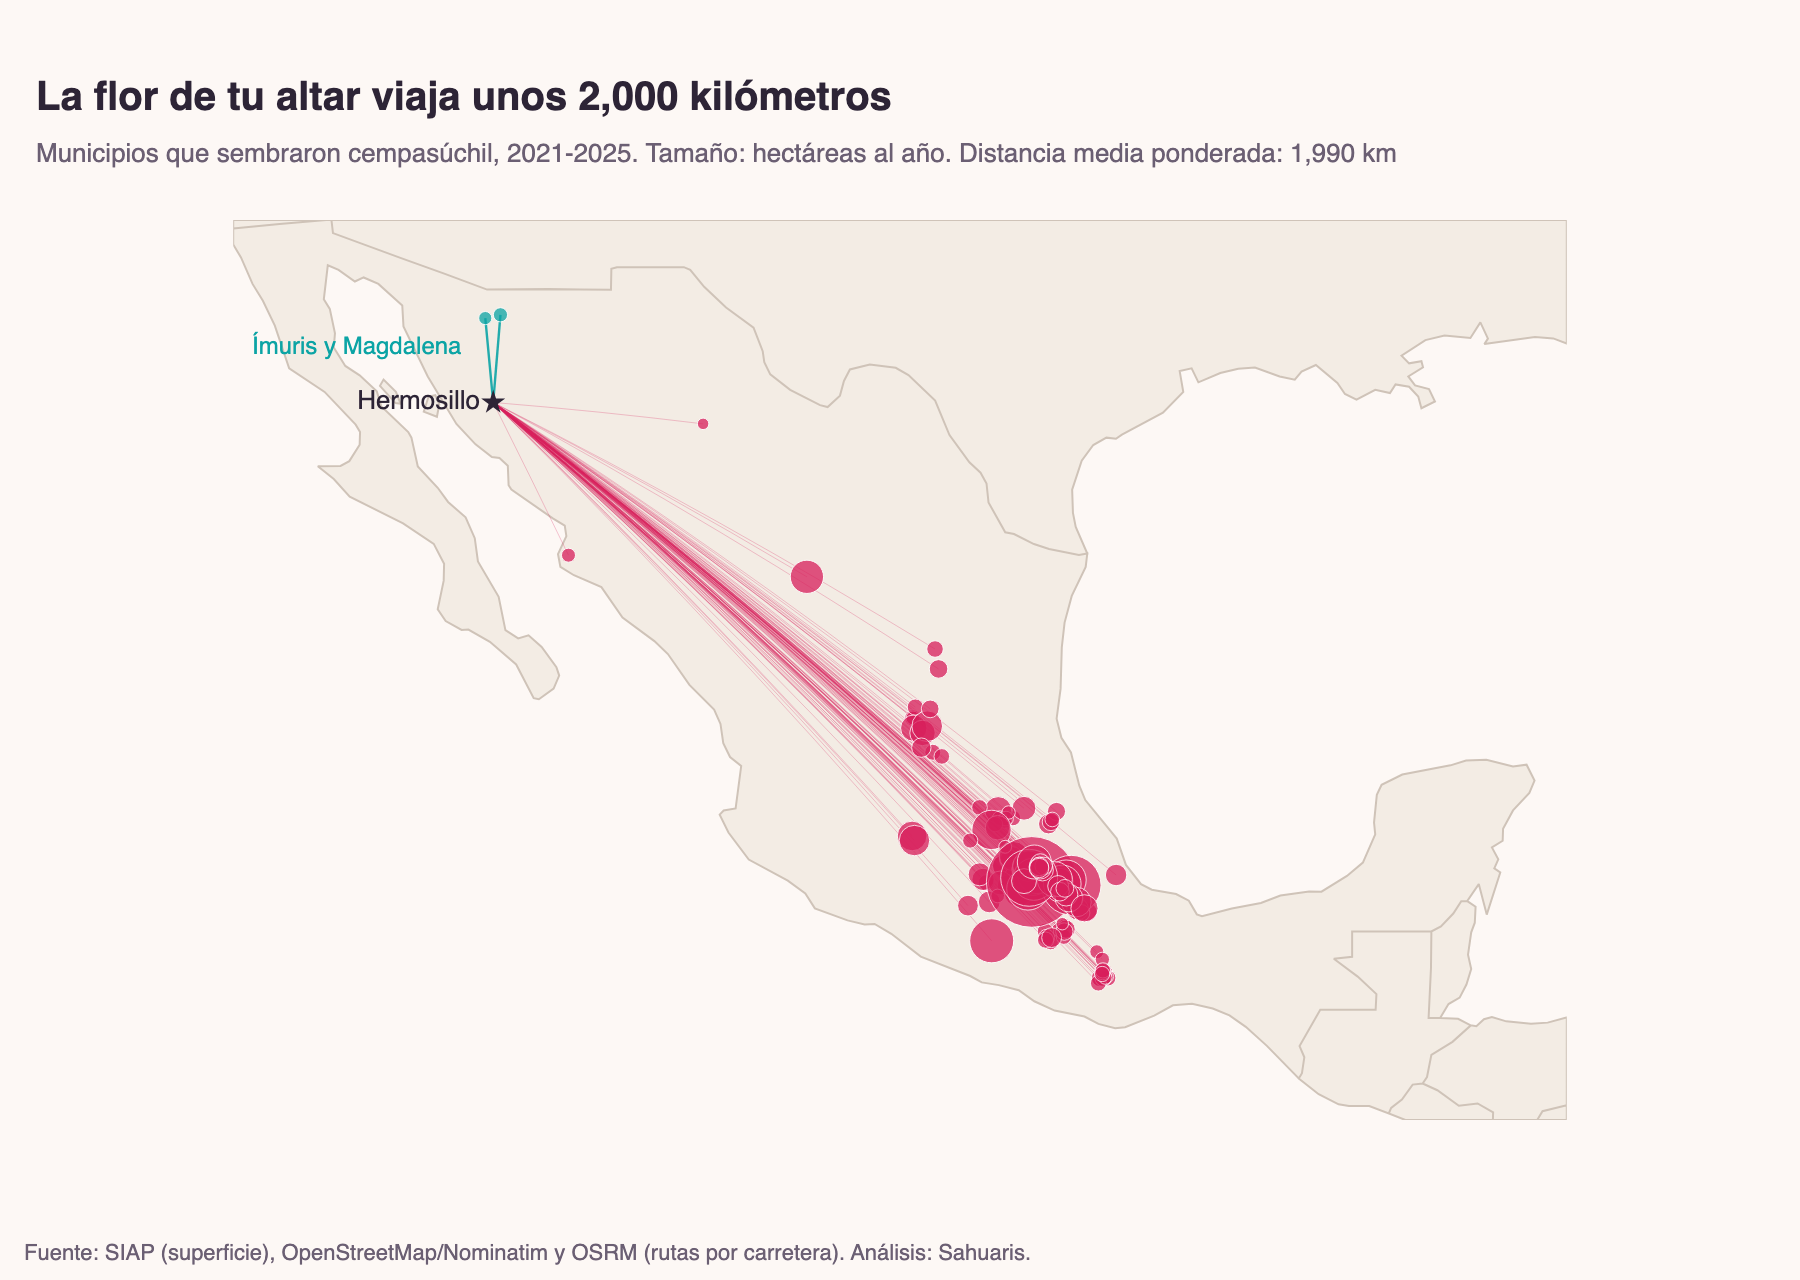

In [5]:
nombre_d, lat_d, lon_d = config.DESTINO
fig = go.Figure()
for fila in con_ruta.itertuples():
    sonora = fila.idestado == config.CVE_ENT_SONORA
    fig.add_trace(go.Scattergeo(
        lon=[fila.lon, lon_d], lat=[fila.lat, lat_d], mode="lines",
        line=dict(width=1.2 if sonora else 0.5, color=tema.SECUNDARIO if sonora else tema.PROTAGONISTA),
        opacity=0.9 if sonora else 0.25, hoverinfo="skip", showlegend=False,
    ))
tamanio = (con_ruta["ha_promedio"] ** 0.5) * 2.2 + 4
fig.add_trace(go.Scattergeo(
    lon=con_ruta["lon"], lat=con_ruta["lat"], mode="markers",
    marker=dict(size=tamanio, color=[tema.SECUNDARIO if e == config.CVE_ENT_SONORA else tema.PROTAGONISTA for e in con_ruta["idestado"]],
                opacity=0.75, line=dict(width=0.5, color="white")),
    text=[f"{m}, {e}<br>{h:,.1f} ha al año · {d:,.0f} km a Hermosillo" for m, e, h, d in zip(con_ruta["nommunicipio"], con_ruta["nomestado"], con_ruta["ha_promedio"], con_ruta["distancia_km"])],
    hovertemplate="%{text}<extra></extra>", showlegend=False,
))
fig.add_trace(go.Scattergeo(lon=[lon_d], lat=[lat_d], mode="markers+text", text=[nombre_d], textposition="middle left",
                            marker=dict(size=9, color=tema.TEXTO, symbol="star"), textfont=dict(color=tema.TEXTO, size=13), hoverinfo="skip", showlegend=False))
fig.add_annotation(x=0.13, y=0.88, xref="paper", yref="paper", text="Ímuris y Magdalena", showarrow=False, font=dict(color=tema.SECUNDARIO, size=12))
fig.update_geos(
    scope="north america", projection_type="mercator",
    lonaxis_range=[-117, -86], lataxis_range=[14, 33],
    showland=True, landcolor="#F3ECE4", showcountries=True, countrycolor=tema.NEUTRO,
    showsubunits=True, subunitcolor="#E2D7CC", showocean=True, oceancolor=tema.FONDO, showlakes=False,
    bgcolor=tema.FONDO, showframe=False,
)
fig.update_layout(
    title=tema.titulo("La flor de tu altar viaja unos 2,000 kilómetros",
                      f"Municipios que sembraron cempasúchil, 2021-2025. Tamaño: hectáreas al año. Distancia media ponderada: {media_ponderada:,.0f} km"),
    height=640, margin=dict(l=10, r=10, t=110, b=80),
)
tema.nota_fuente(fig, "Fuente: SIAP (superficie), OpenStreetMap/Nominatim y OSRM (rutas por carretera). Análisis: Sahuaris.")
tema.mostrar(fig, "04_mapa_viaje", alto=640)

## Superficie por distancia a Hermosillo

Interactiva: outputs/figuras/04_distancia_bandas.html


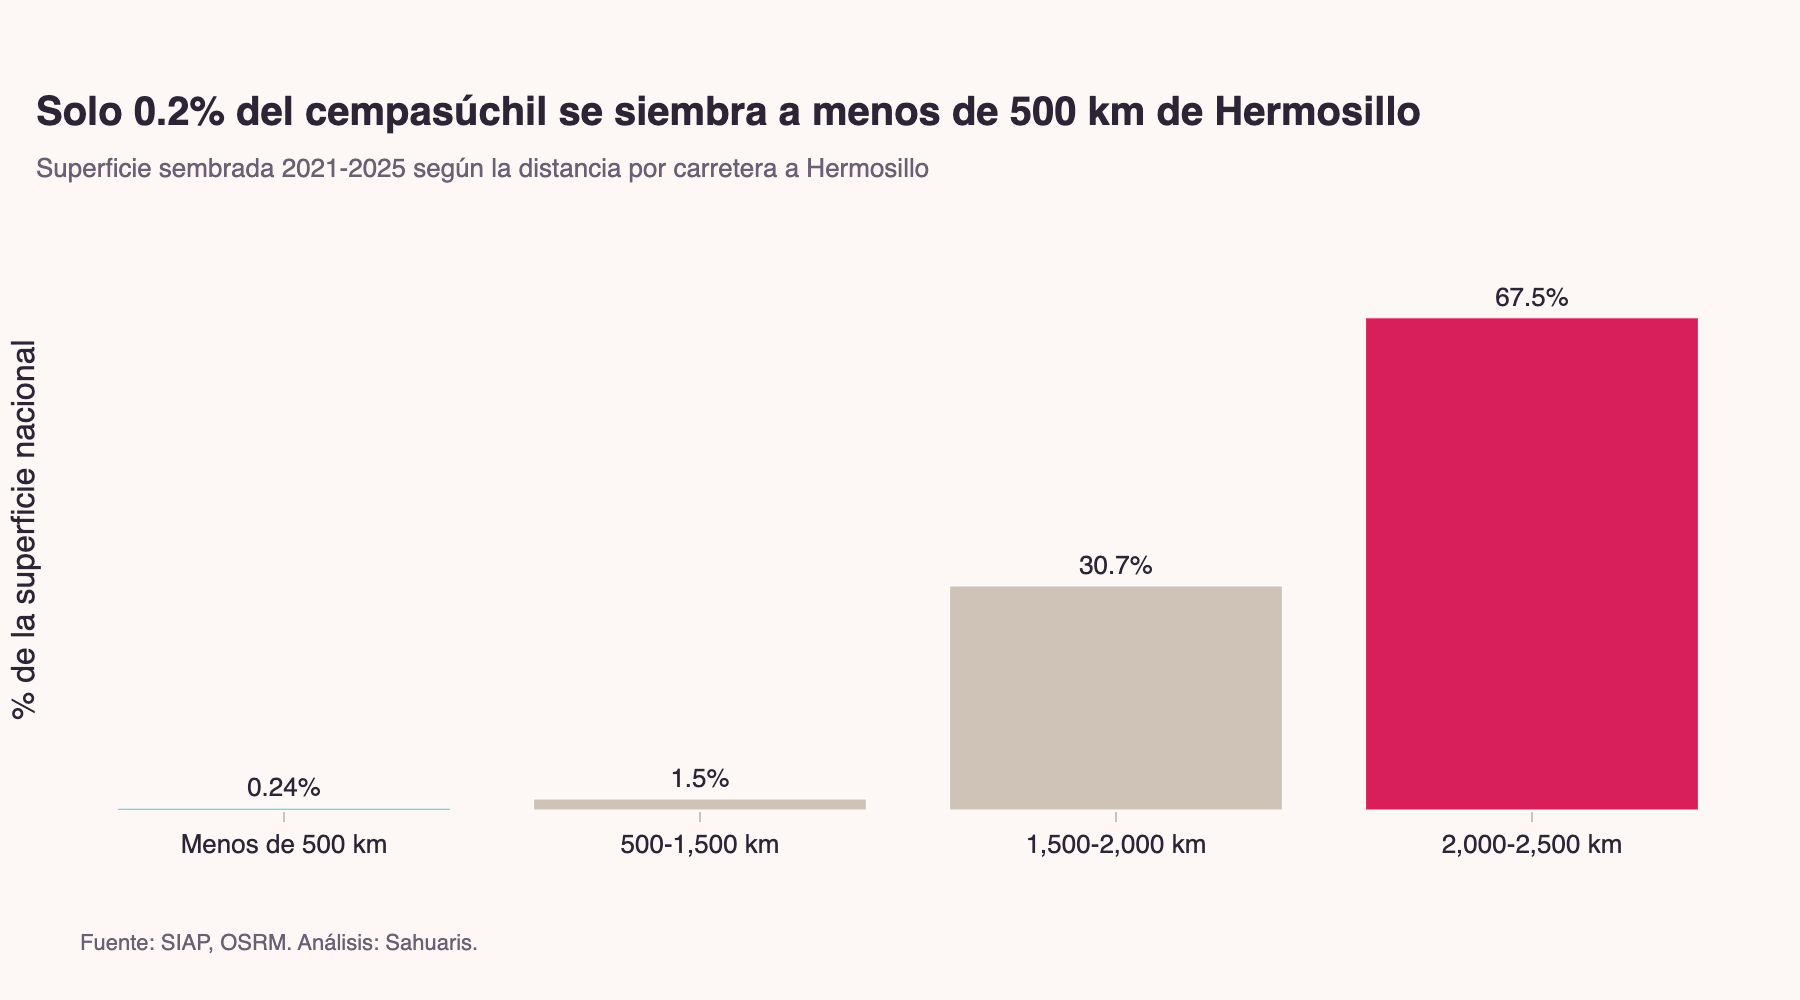

In [6]:
assert con_ruta["distancia_km"].max() < 2500
cortes = [0, 500, 1500, 2000, 2500]
etiquetas = ["Menos de 500 km", "500-1,500 km", "1,500-2,000 km", "2,000-2,500 km"]
con_ruta["banda"] = pd.cut(con_ruta["distancia_km"], cortes, labels=etiquetas, right=False)
bandas = con_ruta.groupby("banda", observed=False)["ha_promedio"].sum()
bandas_pct = bandas / bandas.sum() * 100
fig = go.Figure(go.Bar(
    x=bandas.index.astype(str), y=bandas_pct,
    marker_color=[tema.SECUNDARIO if b == etiquetas[0] else tema.PROTAGONISTA if p == bandas_pct.max() else tema.NEUTRO for b, p in zip(bandas.index, bandas_pct)],
    text=[f"{p:.1f}%" if p >= 1 else f"{p:.2f}%" for p in bandas_pct], textposition="outside", cliponaxis=False,
    hovertemplate="%{x}: %{y:.2f}% de la superficie<extra></extra>",
))
fig.update_layout(
    title=tema.titulo(f"Solo {bandas_pct.iloc[0]:.1f}% del cempasúchil se siembra a menos de 500 km de Hermosillo",
                      "Superficie sembrada 2021-2025 según la distancia por carretera a Hermosillo"),
    xaxis=dict(title=""), yaxis=dict(title="% de la superficie nacional", showticklabels=False, showgrid=False), height=500,
)
tema.nota_fuente(fig, "Fuente: SIAP, OSRM. Análisis: Sahuaris.")
tema.mostrar(fig, "04_distancia_bandas", alto=500)

In [7]:
con_ruta.to_csv(config.DIR_PROCESSED / "viaje_a_hermosillo.csv", index=False)